Part 1 read DNA. Part 2 reads what the cell actually *does* with it, starting with **RNA-seq**: sequencing the messenger RNA to measure how strongly each gene is expressed (prerequisites P4, P6). RNA-seq is the workhorse of modern biology, used to compare diseased and healthy tissue, treated and untreated cells, one cell type and another. This chapter takes you from a raw count matrix to a ranked list of genes that differ between two conditions, honestly, with the statistics done properly, on real data: 200 breast tumours of two molecular subtypes from The Cancer Genome Atlas.

:::eli5
Every cell has the same 20,000 genes but uses a different subset (prerequisite P6). RNA-seq counts how many RNA copies of each gene are floating in a sample: a readout of which genes are "on" and how loudly. To compare two groups of samples, say aggressive versus mild tumours, you look for genes whose counts are consistently different. The hard part is telling a real difference from random noise when you are testing thousands of genes at once, which is what most of this chapter is about.
:::

## From RNA to a count matrix

The RNA-seq pipeline (prerequisite P11): extract RNA, convert it to cDNA, sequence it to get reads, map the reads to the genome (chapter 4), and **count** how many reads fall in each gene. The result is a **count matrix**: genes in rows, samples in columns, each entry the number of reads for that gene in that sample. That matrix is where computational analysis begins.

We downloaded real RSEM gene counts for 200 breast tumours from TCGA: 100 of the aggressive **Basal-like** subtype and 100 of the milder **Luminal A** subtype. These subtypes differ biologically (prerequisite P12), so many genes should differ, a perfect test case.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
import gzip, json
import warnings; warnings.filterwarnings("ignore")

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

counts = pd.read_csv("datasets/brca_rnaseq_counts.csv.gz", index_col=0)
groups = json.load(open("datasets/sample_groups.json"))
basal = [s for s in counts.columns if s in set(groups["basal"])]
luminal = [s for s in counts.columns if s in set(groups["lumA"])]
is_basal = np.array([s in set(groups["basal"]) for s in counts.columns])
print(f"count matrix: {counts.shape[0]:,} genes x {counts.shape[1]} tumours ({len(basal)} Basal, {len(luminal)} Luminal A)")
print(counts.iloc[:4, :4])
R["n_genes"] = f"{counts.shape[0]:,}"; R["n_samples"] = counts.shape[1]

count matrix: 5,993 genes x 200 tumours (100 Basal, 100 Luminal A)
       TCGA-A1-A0SK-01  TCGA-A1-A0SO-01  TCGA-A1-A0SP-01  TCGA-A2-A04P-01
gene                                                                     
A1BG                87              293               37              109
AADAC                0                1                1                0
AARS1             2857             2652             6579             2476
ABCA1              834              317              524              272


## Counts are not comparable as they are

The raw count for a gene depends on three things: how much the gene is expressed (what we want), how long the gene is (longer genes catch more reads), and how deeply the sample was sequenced (its **library size**). The last one is a pure technical artefact, and it is large: sequence one sample twice as deep and every count doubles, with no biological change.

library sizes range from 5,392,167 to 8,694,704 reads (1.6x)


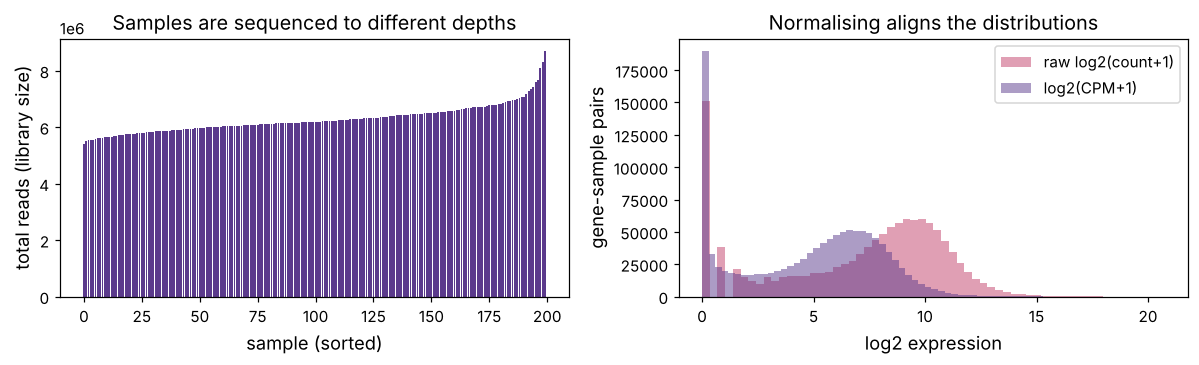

In [2]:
lib_sizes = counts.sum(axis=0)
print(f"library sizes range from {lib_sizes.min():,.0f} to {lib_sizes.max():,.0f} reads ({lib_sizes.max()/lib_sizes.min():.1f}x)")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].bar(range(len(lib_sizes)), np.sort(lib_sizes), color="#5b3a8c")
axs[0].set_xlabel("sample (sorted)"); axs[0].set_ylabel("total reads (library size)"); axs[0].set_title("Samples are sequenced to different depths")

# counts per million (CPM) normalisation, then log
cpm = counts / lib_sizes * 1e6
logcpm = np.log2(cpm + 1)
axs[1].hist(np.log2(counts.values.flatten() + 1), bins=60, alpha=0.5, label="raw log2(count+1)", color="#c2416b")
axs[1].hist(logcpm.values.flatten(), bins=60, alpha=0.5, label="log2(CPM+1)", color="#5b3a8c")
axs[1].set_xlabel("log2 expression"); axs[1].set_ylabel("gene-sample pairs"); axs[1].legend(); axs[1].set_title("Normalising aligns the distributions")
save_fig("library_size"); plt.show()
R["lib_ratio"] = f"{lib_sizes.max()/lib_sizes.min():.1f}"

![Figure 6-1. Left: library sizes vary by several-fold across samples. Right: raw counts versus counts-per-million; normalising by library size makes samples comparable.](images/library_size.png)

Library sizes here vary 1.6-fold. The simplest fix is **counts per million** (CPM): divide each count by the sample's library size and multiply by a million. **TPM** (transcripts per million) additionally divides by gene length, making values comparable *within* a sample. For differential expression, the state-of-the-art normalisations (DESeq2's **median-of-ratios**, edgeR's **TMM**) are more robust: they assume most genes do *not* change and scale samples so that the bulk of genes line up, so a few extremely high genes can't distort the factor. The playground's first tab shows why naive comparison fails and normalisation fixes it.

::playground animations/rnaseq_lab.html 620

## The shape of count data: overdispersion

To test for differences we need a statistical model of the counts. Counts of random events suggest a **Poisson** distribution, whose variance equals its mean. But real RNA-seq counts vary *more* than Poisson across biological replicates, because samples genuinely differ (**biological variability**). This extra spread is **overdispersion**, and ignoring it is the classic way to get thousands of false positives.

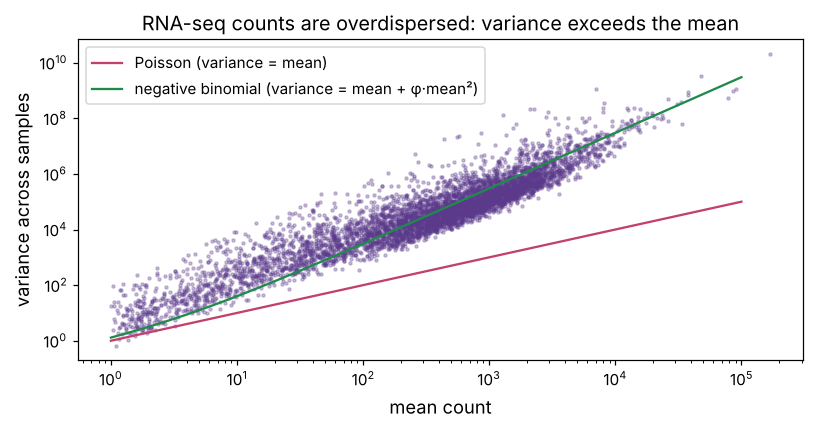

In [3]:
# mean vs variance across the Luminal samples, per gene
sub = logcpm  # work in a stabilised space for display; model below uses counts
lum_counts = counts[luminal].values
gene_mean = lum_counts.mean(axis=1)
gene_var = lum_counts.var(axis=1)
keep = gene_mean > 1
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.scatter(gene_mean[keep], gene_var[keep], s=4, alpha=0.3, color="#5b3a8c")
xx = np.logspace(0, 5, 50)
ax.plot(xx, xx, color="#c2416b", label="Poisson (variance = mean)")
ax.plot(xx, xx + 0.3 * xx ** 2, color="#1f8a4c", label="negative binomial (variance = mean + φ·mean²)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("mean count"); ax.set_ylabel("variance across samples"); ax.legend()
ax.set_title("RNA-seq counts are overdispersed: variance exceeds the mean")
save_fig("overdispersion"); plt.show()
frac_over = np.mean(gene_var[keep] > 2 * gene_mean[keep])
R["frac_over"] = f"{frac_over:.0%}"

![Figure 6-2. Variance versus mean for each gene across the Luminal tumours. If counts were Poisson they would follow the red line; instead variance grows faster, following a negative-binomial curve (green). This extra spread is biological variability.](images/overdispersion.png)

Most genes (99%) have variance well above the mean, far from Poisson. The right model is the **negative binomial**, whose variance is mean + φ·mean² (the dispersion φ captures biological variability). This is the model behind DESeq2 and edgeR, the two standard differential-expression tools. A key trick they use: with only a handful of replicates, each gene's dispersion is poorly estimated, so they **share information across genes**, shrinking each gene's noisy estimate toward the trend, which is why they work with as few as 3 replicates.

## Differential expression: testing one gene

For each gene, we ask: is its mean expression different between Basal and Luminal tumours, by more than we'd expect from noise? With our 100-vs-100 design we have plenty of samples, so a test on log-normalised values is reliable. Let's do it for one gene, then all genes.

In [4]:
from scipy import stats
def test_gene(gene):
    b = logcpm.loc[gene, basal].values
    l = logcpm.loc[gene, luminal].values
    lfc = b.mean() - l.mean()                         # log2 fold change (Basal vs Luminal)
    t, p = stats.ttest_ind(b, l, equal_var=False)
    return lfc, p

for gene in ["ESR1", "FOXA1", "FOXM1", "KRT5", "GATA3"]:
    if gene in logcpm.index:
        lfc, p = test_gene(gene)
        direction = "higher in Basal" if lfc > 0 else "higher in Luminal"
        print(f"{gene:6s}: log2FC {lfc:+.2f} ({direction}), p = {p:.1e}")

ESR1  : log2FC -6.81 (higher in Luminal), p = 3.2e-72
FOXA1 : log2FC -6.31 (higher in Luminal), p = 5.1e-59
FOXM1 : log2FC +2.45 (higher in Basal), p = 1.3e-42
KRT5  : log2FC +2.60 (higher in Basal), p = 7.7e-09
GATA3 : log2FC -4.34 (higher in Luminal), p = 6.2e-41


The known markers come out exactly as the biology predicts (prerequisite P12): the oestrogen receptor **ESR1** and luminal factors **FOXA1**, **GATA3** are far higher in Luminal tumours, while the proliferation gene **FOXM1** and basal keratin **KRT5** are higher in Basal. These genes define the subtypes, and our test recovers them. Now every gene at once:

In [5]:
results = pd.DataFrame({g: test_gene(g) for g in logcpm.index}, index=["log2FC", "pvalue"]).T
results = results.dropna()
print(f"tested {len(results):,} genes; {np.mean(results.pvalue < 0.05):.0%} have p < 0.05")

tested 5,902 genes; 71% have p < 0.05


## The multiple-testing problem

Here is the trap. We tested ~6,000 genes. If none truly differed, a p < 0.05 cutoff would still flag 5% of them, ~300 genes, purely by chance. With thousands of tests, "p < 0.05" is meaningless. We must control the **false discovery rate** (FDR): the expected fraction of our "hits" that are false.

The **Benjamini–Hochberg** procedure does this. Sort the p-values; the FDR-adjusted value (**q-value**) for the gene at rank $i$ out of $m$ is $p_{(i)} \cdot m / i$ (enforced to be monotone). Calling everything with q < 0.05 guarantees that, on average, only 5% of the calls are false.

In [6]:
def benjamini_hochberg(pvalues):
    p = np.asarray(pvalues)
    order = np.argsort(p)
    m = len(p)
    q = np.empty(m)
    q[order] = p[order] * m / (np.arange(m) + 1)
    # enforce monotonicity from the largest p downward
    q_sorted = q[order]
    q_sorted = np.minimum.accumulate(q_sorted[::-1])[::-1]
    q[order] = np.minimum(q_sorted, 1)
    return q

results["qvalue"] = benjamini_hochberg(results.pvalue.values)
n_nominal = int((results.pvalue < 0.05).sum())
n_fdr = int((results.qvalue < 0.05).sum())
print(f"genes with p < 0.05 (naive): {n_nominal:,}")
print(f"genes with FDR q < 0.05 (corrected): {n_fdr:,}")
R["n_nominal"] = f"{n_nominal:,}"; R["n_fdr"] = f"{n_fdr:,}"

genes with p < 0.05 (naive): 4,213
genes with FDR q < 0.05 (corrected): 4,104


Here so many genes genuinely differ between these very different subtypes that most survive, but the correction is what makes any such claim trustworthy. The playground's second tab lets you watch FDR control in action: add replicates to detect more true genes, and see that the false fraction among your hits stays near the threshold you set.

## The volcano plot

The standard summary of a differential-expression analysis is the **volcano plot**: log2 fold change on the x-axis, significance (−log10 p) on the y-axis. Genes that are both strongly changed and highly significant sit at the top corners, the biology worth following up.

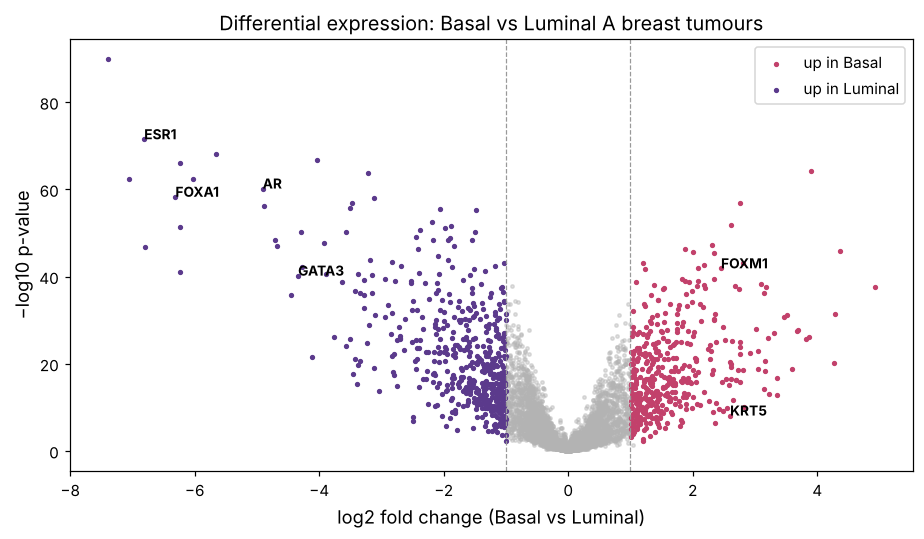

In [7]:
results["neglogp"] = -np.log10(results.pvalue)
sig = (results.qvalue < 0.01) & (results.log2FC.abs() > 1)
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(results.log2FC[~sig], results.neglogp[~sig], s=5, color="0.7", alpha=0.4)
ax.scatter(results.log2FC[sig & (results.log2FC > 0)], results.neglogp[sig & (results.log2FC > 0)], s=6, color="#c2416b", label="up in Basal")
ax.scatter(results.log2FC[sig & (results.log2FC < 0)], results.neglogp[sig & (results.log2FC < 0)], s=6, color="#5b3a8c", label="up in Luminal")
for gene in ["ESR1", "FOXA1", "GATA3", "FOXM1", "KRT5", "AR"]:
    if gene in results.index:
        row = results.loc[gene]
        ax.annotate(gene, (row.log2FC, row.neglogp), fontsize=9, fontweight="bold")
ax.axvline(1, color="0.6", ls="--", lw=0.8); ax.axvline(-1, color="0.6", ls="--", lw=0.8)
ax.set_xlabel("log2 fold change (Basal vs Luminal)"); ax.set_ylabel("−log10 p-value"); ax.legend()
ax.set_title("Differential expression: Basal vs Luminal A breast tumours")
save_fig("volcano"); plt.show()
R["n_up_basal"] = int((sig & (results.log2FC > 1)).sum()); R["n_up_lum"] = int((sig & (results.log2FC < -1)).sum())

![Figure 6-3. Volcano plot of Basal versus Luminal A tumours. Each dot is a gene; coloured genes pass both the FDR and fold-change cutoffs. Labelled markers sit exactly where their biology predicts.](images/volcano.png)

The analysis flags 429 genes significantly up in Basal and 527 up in Luminal (FDR < 1%, |log2FC| > 1). ESR1, FOXA1 and GATA3 are among the strongest Luminal genes; FOXM1 and KRT5 among the strongest Basal genes. We have reproduced, from raw counts, the molecular distinction that defines these clinically important subtypes.

## From gene lists to biology: enrichment

A list of hundreds of genes is not yet understanding. The next step is **enrichment analysis**: are the changed genes concentrated in particular pathways or functions (prerequisite P9)? The simplest version tests whether a gene set (say "cell cycle") appears among your hits more than chance, with a hypergeometric test. Let's check whether Basal-up genes are enriched for proliferation, which would fit their aggressive biology.

In [8]:
from scipy.stats import hypergeom
proliferation = {"FOXM1", "MKI67", "CCNB1", "CDK1", "TOP2A", "BIRC5", "AURKA", "AURKB", "BUB1", "CCNB2",
                 "CDC20", "PLK1", "PTTG1", "UBE2C", "NEK2", "KIF2C", "CENPA", "CENPE", "MYBL2"}
tested = set(results.index)
basal_up = set(results.index[(results.qvalue < 0.01) & (results.log2FC > 1)])
prol_in_bg = proliferation & tested
hits = basal_up & prol_in_bg
# hypergeometric: drawing len(basal_up) genes, how many proliferation genes expected?
M, n, N = len(tested), len(prol_in_bg), len(basal_up)
expected = N * n / M
p_enrich = hypergeom.sf(len(hits) - 1, M, n, N)
print(f"proliferation genes among background: {len(prol_in_bg)}")
print(f"found in Basal-up set: {len(hits)} (expected by chance {expected:.1f}); enrichment p = {p_enrich:.1e}")
print("genes:", sorted(hits))
R["prol_hits"] = len(hits); R["prol_exp"] = f"{expected:.1f}"; R["prol_p"] = f"{p_enrich:.0e}"

proliferation genes among background: 11
found in Basal-up set: 11 (expected by chance 0.8); enrichment p = 2.7e-13
genes: ['AURKB', 'BIRC5', 'BUB1', 'CCNB1', 'CDK1', 'FOXM1', 'KIF2C', 'MYBL2', 'NEK2', 'PTTG1', 'TOP2A']


Proliferation genes are strongly over-represented among the Basal-up genes (11 found, 0.8 expected, p = 3e-13), confirming that Basal tumours are more proliferative, their defining aggressive feature. Real tools (GSEA, Enrichr, g:Profiler) test thousands of curated gene sets (GO terms, KEGG and Reactome pathways, prerequisite P9) this way and are how a raw gene list becomes a biological story.

:::idea
RNA-seq measures mRNA, not protein, and the two correlate only moderately (prerequisite P4): a gene's mRNA can be high while its protein is low, because of translation and degradation control. RNA-seq also measures a population average over all cells in the sample, mixing cell types. Both limitations motivate what comes next, single-cell RNA-seq (chapter 7) resolves the cell mixture, and proteomics and ribosome profiling address the mRNA-protein gap.
:::

## Summary

| Idea | One line |
|---|---|
| Count matrix | genes × samples; the start of RNA-seq analysis |
| Library size | samples sequenced to different depths; must normalise (CPM/TPM/median-of-ratios) |
| Overdispersion | counts vary more than Poisson; use the negative binomial |
| Differential expression | per-gene test for a difference between conditions |
| Multiple testing / FDR | Benjamini–Hochberg controls the false fraction among hits |
| Volcano plot | fold change vs significance; the standard summary |
| Enrichment | are changed genes concentrated in a pathway? |

:::check
1. Why can't you compare raw counts between two samples directly? *(They depend on library size; a deeper-sequenced sample has higher counts everywhere.)*
2. What does overdispersion mean, and which distribution handles it? *(Variance exceeds the mean; the negative binomial.)*
3. You test 10,000 genes at p < 0.05 with none truly changed. Roughly how many false hits? *(About 500.)*
4. What does an FDR (q-value) of 0.05 guarantee? *(On average only 5% of the genes called significant are false.)*
5. Where on a volcano plot are the most interesting genes? *(Top corners: large fold change and high significance.)*
:::

:::exercise
Instead of testing marker genes, let the data find the subtypes. (a) Take the 1,000 most variable genes (by variance of log-CPM across all 200 tumours). (b) Run PCA on them (samples as points). (c) Colour the points by subtype. Do Basal and Luminal separate on the first principal component? This previews chapter 7, where PCA on single cells reveals cell types the same way.
:::

<details><summary>Solution</summary>

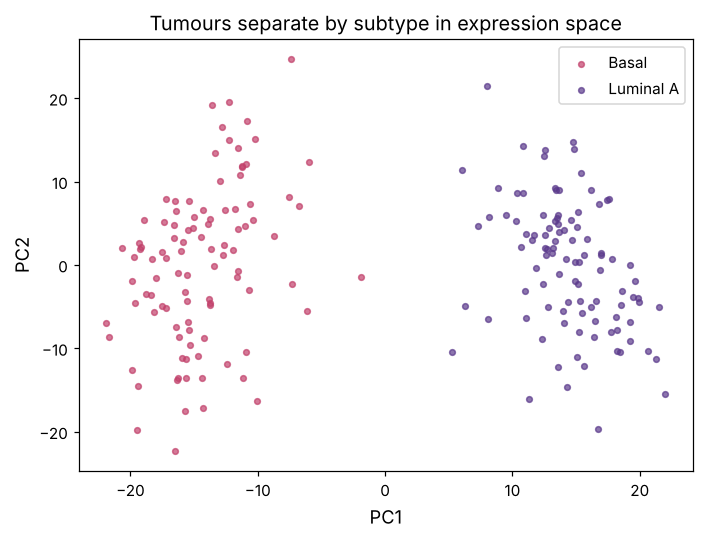

PC1 separation between subtypes: 1.9 standard deviations


In [9]:
from sklearn.decomposition import PCA
top = logcpm.loc[logcpm.var(axis=1).sort_values(ascending=False).index[:1000]]
X = (top.T - top.T.mean()) / (top.T.std() + 1e-9)
pcs = PCA(n_components=2).fit_transform(X)
fig, ax = plt.subplots(figsize=(6.5, 5))
for grp, mask, c in [("Basal", is_basal, "#c2416b"), ("Luminal A", ~is_basal, "#5b3a8c")]:
    ax.scatter(pcs[mask, 0], pcs[mask, 1], s=14, color=c, label=grp, alpha=0.7)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(); ax.set_title("Tumours separate by subtype in expression space")
save_fig("pca_subtypes"); plt.show()
sep = abs(pcs[is_basal, 0].mean() - pcs[~is_basal, 0].mean()) / pcs[:, 0].std()
print(f"PC1 separation between subtypes: {sep:.1f} standard deviations")

The two subtypes separate cleanly along PC1, which captures the dominant axis of variation in the data, here the Basal–Luminal difference, without ever being told the labels. This is the power of **unsupervised** analysis: structure emerges from the expression alone. Chapter 7 applies exactly this idea to tens of thousands of single cells, where the clusters that appear are cell types.

</details>